# Electromagnetic Wave

> Part of *PHYS 0241: Biomedical Imaging* (Prof. Michael E. Durst, Middlebury College). The [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch02/ch02-02.html) shows the rendered version together with the pre-rendered animations (course password required).
>
> **Start here:** run the setup cell below first. In Google Colab, choose **File > Save a copy in Drive** to keep your changes.
>
> *Provided for academic use in PHYS 0241; please do not repost or redistribute ([terms of use](https://github.com/durstme/textbook-biomedicalimaging-notebooks/blob/main/LICENSE.md)).*

In [ ]:
# --- Setup: run this cell first.  It does nothing outside Google Colab. ---
import sys, os, importlib.util, urllib.request
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    # interactive matplotlib (%matplotlib widget) needs ipympl and Colab's custom widget manager
    if importlib.util.find_spec("ipympl") is None:
        get_ipython().run_line_magic("pip", "install -q ipympl")
        importlib.invalidate_caches()  # make the freshly installed package importable
        try:  # matplotlib caches its backend list on first use; refresh it so no restart is needed
            from matplotlib.backends.registry import backend_registry
            backend_registry._clear()
        except Exception:
            pass
    import ipympl  # noqa: F401
    from google.colab import output
    output.enable_custom_widget_manager()
    print("Colab setup done. If a %matplotlib widget cell still errors, use Runtime > Restart session, then Run all.")

## Import libraries

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


In [ ]:
%matplotlib inline
# Define global "bold" style parameters
# This restores the thicker lines and fonts seen in older versions
plot_params = {
    # --- Fonts ---
    'font.size': 18,
    'font.family': 'sans-serif',
    
    # --- Axes (The Box) ---
    'axes.linewidth': 1.0,       # Thicker box around the plot
    
    # --- Lines (The Signal) ---
    'lines.linewidth': 2.5,      # Thicker default plot lines
}

# Apply these settings globally
plt.rcParams.update(plot_params)

## Initialize variables

Here we set the wave to travel along the x-axis with $\vec{k} = (k,0,0)$ and the electric field to be polarized along the z-axis with $\vec{E} = (0,E,0)$. The magnetic field is then along the y-axis with $\vec{B} = (0,0,B)$.

#### Unnecessary Details
Just for fun, we check to make sure that the electric field and the wavevector are perpendicular by taking the dot product.  (We let `numpy` handle the vector math using `np.dot` for the dot product and `np.cross` for the cross product.) This provides the component of the electric field in the direction of the wavevector, which should be zero.  Even if it is not zero, we subtract that component from the electric field to make it perpendicular.

To make the B-field perpendicular, we take the cross product between the wavevector and the (corrected) electric field.

### Resulting Field
The expression for the electric field as a function of position and time is then
$$ E(\vec{r},t) = E_0 \sin(\vec{k} \cdot \vec{r} - \omega t) $$
and the magnetic field is
$$ B(\vec{r},t) = B_0 \sin(\vec{k} \cdot \vec{r} - \omega t) $$
We again let `numpy` handle the vector math.



In [2]:
# Define propagation direction (1,0,0) and normalize
k1 = np.array([1,0,0])  # wave vector / propagation direction
k1_mag = np.linalg.norm(k1)  # magnitude of wave vector
k1_hat = k1/k1_mag  # unit vector in direction of propagation

# Define electric field direction (and ensure perpendicular to k_hat)
E1_desired = np.array([0,1,0])  # desired electric field direction
E1_k1_projection = np.dot(E1_desired, k1_hat)*k1_hat  # component of electric field projected along k_hat
E1_corrected = E1_desired - E1_k1_projection  # corrected electric field (perpendicular to k_hat because parallel component is subtracted)
E1_hat = E1_corrected/np.linalg.norm(E1_corrected)  # unit vector in direction of E field

# Define magnetic field direction (perpendicular to both k_hat and E_hat)
B1_hat = np.cross(k1_hat,E1_hat)  # magnetic field direction from right-hand rule (perpendicular to both k_hat and E_hat due to cross product)
B1_hat = B1_hat/np.linalg.norm(B1_hat)  # unit vector

omega1 = 1.0  # angular frequency (to create a speed for propagation)
numpoints1space = 64 # number of points in space
numpoints1time = 32 # number of time points
s1 = np.linspace(-2*np.pi, 2*np.pi, numpoints1space) # make list of positions along length of wave for plotting line
positions1 = np.outer(s1, k1_hat)  # compute x,y,z positions along wave
# s1arrows = np.linspace(0, 2*np.pi, 8) # make list of positions along length of wave for plotting arrows
t1 = np.linspace(0, 2*np.pi, numpoints1time) # make list of positions along length of wave for plotting line

E1dir = np.outer(np.sin(k1_mag*np.dot(positions1, k1_hat) - omega1*t1[0]),E1_hat)  # directions of E1 vector
B1dir = np.outer(np.sin(k1_mag*np.dot(positions1, k1_hat) - omega1*t1[0]),B1_hat)  # directions of B1 vector
E1line = positions1 + E1dir  # positions of tips of E1 vector (the actual line)
B1line = positions1 + B1dir  # positions of tips of B1 vector (the actual line)

## Make 3D plot with Matplotlib

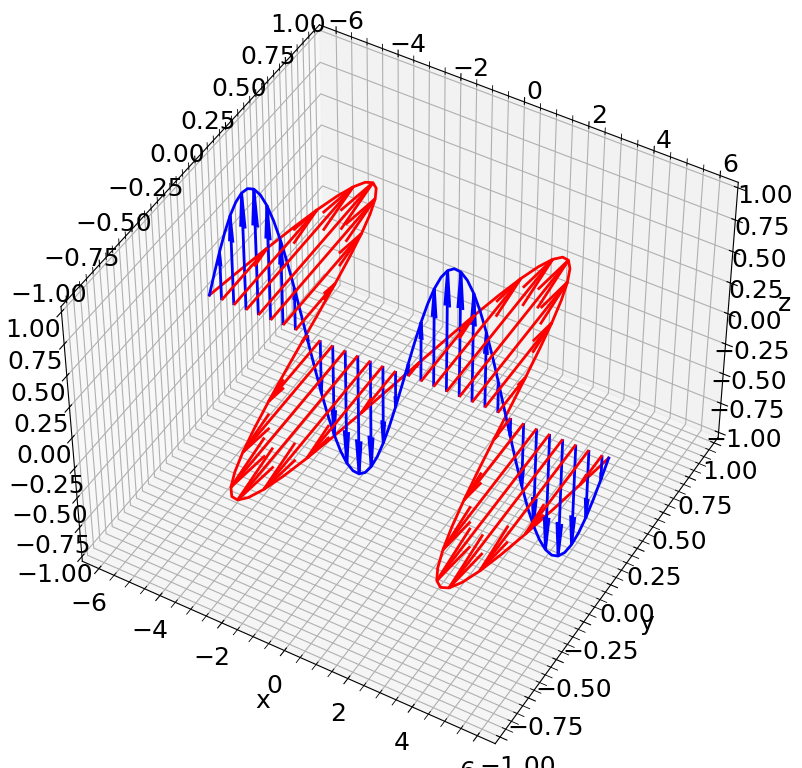

In [3]:
# Set up figure and axis
fig1 = plt.figure(figsize=(10, 8))
ax1 = fig1.add_subplot(111, projection='3d')

# Plot lines
# Plot arrows
plotE1 = ax1.plot(E1line[:,0], E1line[:,1], E1line[:,2], color='red', label='E field', linewidth=2)
plotB1 = ax1.plot(B1line[:,0], B1line[:,1], B1line[:,2], color='blue', label='B field', linewidth=2)

# Plot arrows
plotE1 = ax1.quiver(positions1[::2,0], positions1[::2,1], positions1[::2,2], E1dir[::2,0], E1dir[::2,1], E1dir[::2,2], color='red', label='E field', linewidth=2)
plotB1 = ax1.quiver(positions1[::2,0], positions1[::2,1], positions1[::2,2], B1dir[::2,0], B1dir[::2,1], B1dir[::2,2], color='blue', label='B field', linewidth=2)

# Set labels and title
ax1.set_xlabel('x')
ax1.set_ylabel('y')
ax1.set_zlabel('z')
# ax1.set_title('3D Plane Wave with Multiple Phase Surfaces')

# set the tick mark parameters
ax1.minorticks_on()
ax1.tick_params(which='both',direction="in",width=1)
ax1.tick_params(which='major',length=7)
ax1.tick_params(which='minor',length=3.5)
ax1.xaxis.set_ticks_position('both')
ax1.yaxis.set_ticks_position('both')
ax1.zaxis.set_ticks_position('both')

# set axes limits
ax1.set_xlim(-2*np.pi, 2*np.pi)
ax1.set_ylim(-1, 1)
ax1.set_zlim(-1, 1)


ax1.view_init(elev=45, azim=-60)

# show the plot
plt.tight_layout()
plt.show()


### Interactive plot with `matplotlib` and `ipywidgets`

In [ ]:
%matplotlib widget
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import ipywidgets as widgets
from IPython.display import display

# --- 1. CONFIGURATION ---
n_space = 64        
n_time = 60         
arrow_stride = 2    

# Physics Vectors
k1 = np.array([1, 0, 0]); k1 = k1 / np.linalg.norm(k1)
E1_desired = np.array([0, 1, 0])
E1_corr = E1_desired - np.dot(E1_desired, k1) * k1
E1_hat = E1_corr / np.linalg.norm(E1_corr)
B1_hat = np.cross(k1, E1_hat)
omega = 1.0

# Generate Spatial Grid
s = np.linspace(-2*np.pi, 2*np.pi, n_space)
positions = np.outer(s, k1)
dot_k_pos = np.dot(positions, k1)

# --- 2. PRE-CALCULATION ---
# (Same math as before, just hidden for brevity)
t_max = 2 * np.pi
time_steps = np.linspace(0, t_max, n_time)
cache_E_lines, cache_B_lines = [], []
cache_E_quiver, cache_B_quiver = [], []

for t in time_steps:
    phase = dot_k_pos - omega * t
    E_dirs = np.outer(np.sin(phase), E1_hat)
    B_dirs = np.outer(np.sin(phase), B1_hat)
    E_line = positions + E_dirs
    B_line = positions + B_dirs
    
    cache_E_lines.append((E_line[:,0], E_line[:,1], E_line[:,2]))
    cache_B_lines.append((B_line[:,0], B_line[:,1], B_line[:,2]))
    
    sub = slice(None, None, arrow_stride)
    cache_E_quiver.append((positions[sub,0], positions[sub,1], positions[sub,2], 
                           E_dirs[sub,0], E_dirs[sub,1], E_dirs[sub,2]))
    cache_B_quiver.append((positions[sub,0], positions[sub,1], positions[sub,2], 
                           B_dirs[sub,0], B_dirs[sub,1], B_dirs[sub,2]))

# --- 3. PLOT SETUP ---
fig = plt.figure(figsize=(9, 6))
fig.canvas.header_visible = False
fig.canvas.toolbar_visible = False # Clean look

ax = fig.add_subplot(111, projection='3d')

# Initial Draw
x, y, z = cache_E_lines[0]
l_E, = ax.plot(x, y, z, color='red', label='E field', linewidth=2)
x, y, z = cache_B_lines[0]
l_B, = ax.plot(x, y, z, color='blue', label='B field', linewidth=2)

qx, qy, qz, qu, qv, qw = cache_E_quiver[0]
q_E = ax.quiver(qx, qy, qz, qu, qv, qw, color='red', length=1.0)
qx, qy, qz, qu, qv, qw = cache_B_quiver[0]
q_B = ax.quiver(qx, qy, qz, qu, qv, qw, color='blue', length=1.0)

ax.set_xlabel('x'); ax.set_ylabel('y'); ax.set_zlabel('z')
ax.set_xlim(-2*np.pi, 2*np.pi); ax.set_ylim(-1.5, 1.5); ax.set_zlim(-1.5, 1.5)
ax.view_init(elev=45, azim=-60)
ax.legend(loc='upper right')
plt.tight_layout()

# --- 4. INTERACTIVE WIDGETS ---

# The Play Button
play = widgets.Play(
    value=0,
    min=0,
    max=n_time - 1,
    step=1,
    interval=50,  # Speed in ms (lower = faster)
    description="Press play",
    disabled=False
)

# The Slider (Linked to Play button)
slider = widgets.IntSlider(
    value=0,
    min=0,
    max=n_time - 1,
    step=1,
    description='Time Frame:',
    continuous_update=True
)

# Link them so moving one moves the other
widgets.jslink((play, 'value'), (slider, 'value'))

# The Update Function
def update_plot(change):
    idx = change['new']
    
    # Update Lines
    l_E.set_data(cache_E_lines[idx][0], cache_E_lines[idx][1])
    l_E.set_3d_properties(cache_E_lines[idx][2])
    
    l_B.set_data(cache_B_lines[idx][0], cache_B_lines[idx][1])
    l_B.set_3d_properties(cache_B_lines[idx][2])
    
    # Update Quivers
    global q_E, q_B
    q_E.remove()
    q_B.remove()
    
    qx, qy, qz, qu, qv, qw = cache_E_quiver[idx]
    q_E = ax.quiver(qx, qy, qz, qu, qv, qw, color='red', length=1.0)
    
    qx, qy, qz, qu, qv, qw = cache_B_quiver[idx]
    q_B = ax.quiver(qx, qy, qz, qu, qv, qw, color='blue', length=1.0)
    
    fig.canvas.draw_idle()

# Listen to the slider
slider.observe(update_plot, names='value')

# Display everything
ui = widgets.HBox([play, slider])
display(ui)

### Display animation with javascript from standalone html
[Link to animation](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch02/ch02-02_animation.html)

*Animation.* The pre-rendered animation for this section is shown on the [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch02/ch02-02.html) (direct link: [ch02-02_animation.html](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch02/ch02-02_animation.html)). It is not embedded here because Colab cannot load files from the textbook site; running the code above produces the live version.